# 003 Softmax 分类器：题目要求

**需要完成：** 实现稳定的循环和向量化交叉熵；检查梯度与计时；验证集选择学习率和正则化；报告测试结果并可视化权重；解释随机初始化损失。

**实验范围与验收：** 验证准确率约 35% 为原题参考目标；不是通过改用测试集挑参来达到。

**阅读顺序：** 先阅读原题和代码块前的中文解析，再检查实际输出与问题记录；若本题包含方法二，它紧随对应方法一，使用独立状态。方法一不得依赖方法二才能运行。

**课程参考：** [CS231n 课程资料](https://cs231n.github.io/)。本题的实现、检查和实验结果按下文顺序记录。


# Softmax 练习


*完成并连同作业上交你完整的工作表(包括其输出及工作表外的任何支持代码)，更多详情请参见课程网站上的[作业页面](http://vision.stanford.edu/teaching/cs231n/assignments.html)。*

这个练习类似于SVM练习,你会:
- 为Softmax分类器实现一个完全向量化的**损耗函数**
- 实现其**解析梯度**的全向量化表达式
- **检查你的实现**与数值梯度
- 使用验证集**调整学习率和正则化**强度
- 用**SGD优化**损耗函数
- **可视化**最后学习的重量


**本段解析**

固定 NumPy 与 Python 随机种子为 231，读取共享数据配置，并限制 BLAS 线程数量。这样既能运行验证初始化和抽样，也能避免小矩阵运算中线程调度开销；原始数据文件保持不变。

In [1]:
# 固定实验起点；读取共享数据路径；限制 BLAS 线程，避免多线程调度开销。
import os, sys, random
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from study_runtime import data_path
import numpy as np
from threadpoolctl import threadpool_limits
_blas_limit = threadpool_limits(limits=4)
np.random.seed(231)
random.seed(231)


**本段解析**

导入数组、图像数据读取和绘图依赖。本题将沿用线性分类器训练框架，但把 hinge 损失替换为交叉熵；损失和梯度实现保持在本作业的 softmax.py 中。

In [2]:
import random
import numpy as np
from cs231n.data_utils import load_CIFAR10
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.figsize'] = (12.0, 9.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# for auto-reloading extenrnal modules
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

**本段解析**

读取共享 CIFAR-10，划分 49000/1000 训练验证样本和题目指定的测试、开发子集。展平后只用训练均值中心化，再追加偏置常数列；输出的所有 X 均具有 3073 列。

In [3]:
def get_CIFAR10_data(num_training=49000, num_validation=1000, num_test=1000, num_dev=500):
  """
  Load the CIFAR-10 dataset from disk and perform preprocessing to prepare
  it for the linear classifier. These are the same steps as we used for the
  SVM, but condensed to a single function.  
  """
  # Load the raw CIFAR-10 data
  cifar10_dir = 'cs231n/datasets/cifar-10-batches-py'
  X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)
  
  # subsample the data
  mask = range(num_training, num_training + num_validation)
  X_val = X_train[mask]
  y_val = y_train[mask]
  mask = range(num_training)
  X_train = X_train[mask]
  y_train = y_train[mask]
  mask = range(num_test)
  X_test = X_test[mask]
  y_test = y_test[mask]
  mask = np.random.choice(num_training, num_dev, replace=False)
  X_dev = X_train[mask]
  y_dev = y_train[mask]
  
  # Preprocessing: reshape the image data into rows
  X_train = np.reshape(X_train, (X_train.shape[0], -1))
  X_val = np.reshape(X_val, (X_val.shape[0], -1))
  X_test = np.reshape(X_test, (X_test.shape[0], -1))
  X_dev = np.reshape(X_dev, (X_dev.shape[0], -1))
  
  # Normalize the data: subtract the mean image
  mean_image = np.mean(X_train, axis = 0)
  X_train -= mean_image
  X_val -= mean_image
  X_test -= mean_image
  X_dev -= mean_image
  
  # add bias dimension and transform into columns
  X_train = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
  X_val = np.hstack([X_val, np.ones((X_val.shape[0], 1))])
  X_test = np.hstack([X_test, np.ones((X_test.shape[0], 1))])
  X_dev = np.hstack([X_dev, np.ones((X_dev.shape[0], 1))])
  
  return X_train, y_train, X_val, y_val, X_test, y_test, X_dev, y_dev


# Invoke the above function to get our data.
X_train, y_train, X_val, y_val, X_test, y_test, X_dev, y_dev = get_CIFAR10_data()
print ('Train data shape: ', X_train.shape)
print ('Train labels shape: ', y_train.shape)
print ('Validation data shape: ', X_val.shape)
print ('Validation labels shape: ', y_val.shape)
print ('Test data shape: ', X_test.shape)
print ('Test labels shape: ', y_test.shape)
print ('dev data shape: ', X_dev.shape)
print ('dev labels shape: ', y_dev.shape)

Train data shape:  (49000, 3073)
Train labels shape:  (49000,)
Validation data shape:  (1000, 3073)
Validation labels shape:  (1000,)
Test data shape:  (1000, 3073)
Test labels shape:  (1000,)
dev data shape:  (500, 3073)
dev labels shape:  (500,)


## Softmax 分类器

本节的代码将全部写在**cs231n/classifier /softmax.py**中


**本段解析**

初始化很小的权重，运行逐样本逐类别的 Softmax 损失。先减去样本最大 logit，再指数归一化，计算正确类别的负对数概率和 L2 正则化；随机小权重通常给出接近 log(10) 的初始损失。

In [4]:
# First implement the naive softmax loss function with nested loops.
# Open the file cs231n/classifiers/softmax.py and implement the
# softmax_loss_naive function.

from cs231n.classifiers.softmax import softmax_loss_naive
import time

# Generate a random softmax weight matrix and use it to compute the loss.
W = np.random.randn(3073, 10) * 0.0001
loss, grad = softmax_loss_naive(W, X_dev, y_dev, 0.0)

# As a rough sanity check, our loss should be something close to -log(0.1).
print ('loss: %f' % loss)
print ('sanity check: %f' % (-np.log(0.1)))

loss: 2.377736
sanity check: 2.302585


## Inline Question 1：为什么初始损失接近 −log(0.1)？

**我的分析：** 初始化权重很小时，十类 logits 的差异通常很小，Softmax 概率接近均匀分布，每类约为 0.1，因此正确类别的负对数概率接近 −log(0.1)=log(10)。这只是近似，不是所有随机权重必然产生完全相同的得分；总损失还可能包含正则项。

**本段解析**

使用中心差分检查解析梯度，并分别测试正则项为零和非零的情形。梯度为 Xᵀ(p−one_hot(y))/N 加上正则导数；数值梯度必须和解析实现采用相同损失缩放约定。

In [5]:
# Complete the implementation of softmax_loss_naive and implement a (naive)
# version of the gradient that uses nested loops.
loss, grad = softmax_loss_naive(W, X_dev, y_dev, 0.0)

# As we did for the SVM, use numeric gradient checking as a debugging tool.
# The numeric gradient should be close to the analytic gradient.
from cs231n.gradient_check import grad_check_sparse
f = lambda w: softmax_loss_naive(w, X_dev, y_dev, 0.0)[0]
grad_numerical = grad_check_sparse(f, W, grad, 10)

# similar to SVM case, do another gradient check with regularization
loss, grad = softmax_loss_naive(W, X_dev, y_dev, 1e2)
f = lambda w: softmax_loss_naive(w, X_dev, y_dev, 1e2)[0]
grad_numerical = grad_check_sparse(f, W, grad, 10)

numerical: -0.252974 analytic: -0.252974, relative error: 8.345005e-08
numerical: -0.520432 analytic: -0.520432, relative error: 4.929322e-08
numerical: 0.996365 analytic: 0.996365, relative error: 1.195301e-07


numerical: -0.812374 analytic: -0.812374, relative error: 1.012953e-07
numerical: 2.982623 analytic: 2.982623, relative error: 8.663633e-09
numerical: -0.457827 analytic: -0.457827, relative error: 1.656339e-07


numerical: 2.254471 analytic: 2.254471, relative error: 7.828650e-09
numerical: 0.711863 analytic: 0.711863, relative error: 1.435405e-07
numerical: -1.858907 analytic: -1.858907, relative error: 1.673819e-08


numerical: -2.607389 analytic: -2.607389, relative error: 1.057527e-08
numerical: -2.715878 analytic: -2.715878, relative error: 7.910693e-09
numerical: 1.475838 analytic: 1.475838, relative error: 4.165432e-08


numerical: 1.618027 analytic: 1.618027, relative error: 5.162230e-08
numerical: -1.625039 analytic: -1.625039, relative error: 3.005737e-08
numerical: -4.394898 analytic: -4.394898, relative error: 1.634397e-09


numerical: -1.906243 analytic: -1.906243, relative error: 1.610078e-08
numerical: -2.711260 analytic: -2.711260, relative error: 6.174045e-09
numerical: -3.073989 analytic: -3.073989, relative error: 1.167431e-09


numerical: 1.474522 analytic: 1.474522, relative error: 3.017132e-08
numerical: -1.105881 analytic: -1.105881, relative error: 3.434687e-09


**本段解析**

在相同输入上对比循环和矩阵版本的损失、梯度及耗时。向量化用整批 logits、按行归一化和一次矩阵乘法替代 Python 循环，预期结果一致；逐行减最大值只改变数值计算方式，不改变分类概率。

In [6]:
# Now that we have a naive implementation of the softmax loss function and its gradient,
# implement a vectorized version in softmax_loss_vectorized.
# The two versions should compute the same results, but the vectorized version should be
# much faster.
tic = time.time()
loss_naive, grad_naive = softmax_loss_naive(W, X_dev, y_dev, 0.00001)
toc = time.time()
print ('naive loss: %e computed in %fs' % (loss_naive, toc - tic))

from cs231n.classifiers.softmax import softmax_loss_vectorized
tic = time.time()
loss_vectorized, grad_vectorized = softmax_loss_vectorized(W, X_dev, y_dev, 0.00001)
toc = time.time()
print ('vectorized loss: %e computed in %fs' % (loss_vectorized, toc - tic))

# As we did for the SVM, we use the Frobenius norm to compare the two versions
# of the gradient.
grad_difference = np.linalg.norm(grad_naive - grad_vectorized, ord='fro')
print ('Loss difference: %f' % np.abs(loss_naive - loss_vectorized))
print ('Gradient difference: %f' % grad_difference)

naive loss: 2.377736e+00 computed in 0.042268s


vectorized loss: 2.377736e+00 computed in 0.002001s
Loss difference: 0.000000
Gradient difference: 0.000000


**本段解析**

对学习率与正则强度组合分别训练 5000 次迭代，并计算训练和验证准确率。每组都创建新的 Softmax 分类器，best_softmax 仅保存验证表现最好的实例；原始训练数据和测试标签不参与模型筛选。

In [7]:
# Use the validation set to tune hyperparameters (regularization strength and
# learning rate). You should experiment with different ranges for the learning
# rates and regularization strengths; if you are careful you should be able to
# get a classification accuracy of over 0.35 on the validation set.
from cs231n.classifiers import Softmax
results = {}
best_val = -1
best_softmax = None
learning_rates = [1e-7, 5e-7]
regularization_strengths = [5e4, 1e6]

################################################################################
# TODO:                                                                        #
# Use the validation set to set the learning rate and regularization strength. #
# This should be identical to the validation that you did for the SVM; save    #
# the best trained softmax classifer in best_softmax.                          #
################################################################################
for rate in learning_rates:
    for reg in regularization_strengths:
        sm = Softmax()
        loss_hist = sm.train(X_train, y_train, learning_rate=rate, reg=reg, num_iters=5000, verbose=True)
        y_train_pred = sm.predict(X_train)
        acc_tr = np.mean(y_train == y_train_pred)
        y_val_pred = sm.predict(X_val)
        acc_val = np.mean(y_val == y_val_pred)
        
        results[(rate, reg)] = (acc_tr, acc_val)
        if acc_val > best_val:
            best_val = acc_val
            best_softmax = sm
################################################################################
#                              END OF YOUR CODE                                #
################################################################################
    
# Print out results.
for lr, reg in sorted(results):
    train_accuracy, val_accuracy = results[(lr, reg)]
    print ('lr %e reg %e train accuracy: %f val accuracy: %f' % (
                lr, reg, train_accuracy, val_accuracy))
    
print ('best validation accuracy achieved during cross-validation: %f' % best_val)

iteration 0 / 5000: loss 774.869690
iteration 100 / 5000: loss 284.363219


iteration 200 / 5000: loss 105.331707
iteration 300 / 5000: loss 39.792216


iteration 400 / 5000: loss 15.928819
iteration 500 / 5000: loss 7.154405


iteration 600 / 5000: loss 3.986797
iteration 700 / 5000: loss 2.742282


iteration 800 / 5000: loss 2.316000
iteration 900 / 5000: loss 2.199906


iteration 1000 / 5000: loss 2.082617
iteration 1100 / 5000: loss 2.134504


... (91 outputs left out)

iteration 4400 / 5000: loss 2.281107
iteration 4500 / 5000: loss 2.261821


iteration 4600 / 5000: loss 2.259858
iteration 4700 / 5000: loss 2.272878


iteration 4800 / 5000: loss 2.269788
iteration 4900 / 5000: loss 2.277214


lr 1.000000e-07 reg 5.000000e+04 train accuracy: 0.325347 val accuracy: 0.337000
lr 1.000000e-07 reg 1.000000e+06 train accuracy: 0.243000 val accuracy: 0.261000
lr 5.000000e-07 reg 5.000000e+04 train accuracy: 0.332510 val accuracy: 0.346000
lr 5.000000e-07 reg 1.000000e+06 train accuracy: 0.226306 val accuracy: 0.248000
best validation accuracy achieved during cross-validation: 0.346000


**本段解析**

绘制变量 loss_hist 所对应的最近一次配置的损失轨迹。该变量不一定属于 best_softmax，因此曲线需要结合最后一组超参数理解，不能自动标为最佳模型训练曲线。

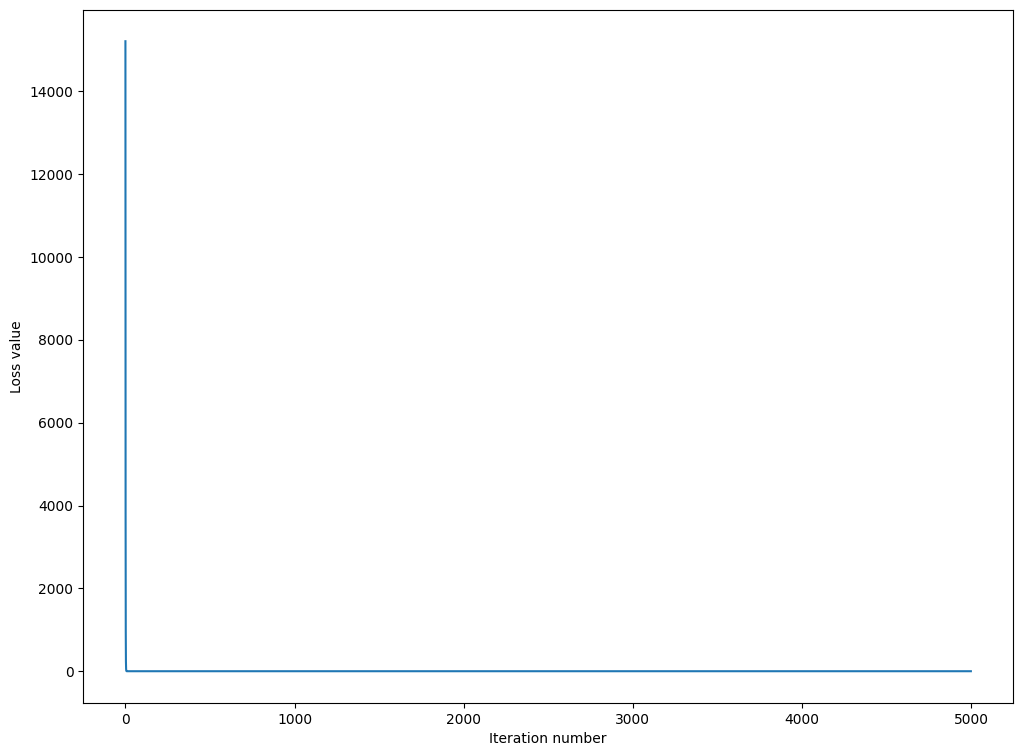

In [8]:
# A useful debugging strategy is to plot the loss as a function of
# iteration number:
plt.plot(loss_hist)
plt.xlabel('Iteration number')
plt.ylabel('Loss value')
plt.show()

**本段解析**

使用已选定的 best_softmax 对测试特征计算得分并取最大类别，输出正确预测的比例。Softmax 概率解释有助于训练，但最终分类标签与 logits 的 argmax 相同。

In [9]:
# evaluate on test set
# Evaluate the best softmax on test set
y_test_pred = best_softmax.predict(X_test)
test_accuracy = np.mean(y_test == y_test_pred)
print ('softmax on raw pixels final test set accuracy: %f' % (test_accuracy, ))

softmax on raw pixels final test set accuracy: 0.352000

**本段解析**

去除偏置后把十列分类权重重排为彩色图像。统一的最小最大值用于显示，不改变模型参数；与 SVM 权重比较时应同时考虑损失函数及正则化设置差异。

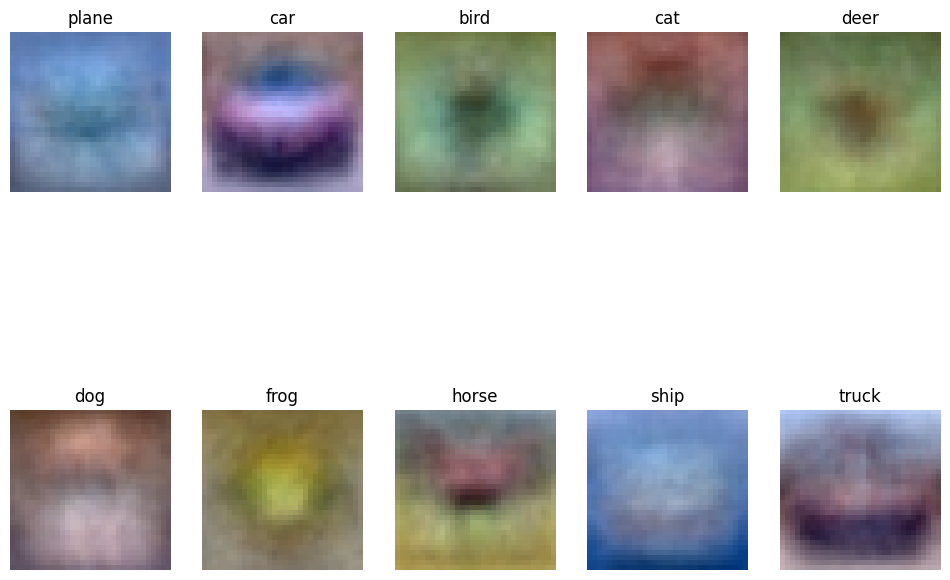

In [10]:
# Visualize the learned weights for each class
w = best_softmax.W[:-1,:] # strip out the bias
w = w.reshape(32, 32, 3, 10)

w_min, w_max = np.min(w), np.max(w)

classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
for i in range(10):
  plt.subplot(2, 5, i + 1)
  
  # Rescale the weights to be between 0 and 255
  wimg = 255.0 * (w[:, :, :, i].squeeze() - w_min) / (w_max - w_min)
  plt.imshow(wimg.astype('uint8'))
  plt.axis('off')
  plt.title(classes[i])

### 保存本次实验
输入是上面实际训练得到的模型、指标和曲线。只保存模型参数与实验结果，不复制原始数据；输出写入本题独立目录，供运行验证核对。

In [11]:
from study_runtime import save_experiment
experiment_metrics = save_experiment(globals(), '003_Softmax')


本机实验指标： {'best_val': 0.346, 'test_accuracy': 0.352, 'acc_tr': 0.2263061224489796, 'acc_val': 0.248}


## 实践补充：问题、检查与方法选择

**实际修复。** 极端 logits 下原指数计算溢出；逐行减最大值后，损失与梯度保持有限，普通输入与循环版本一致。

**结果解释。** 最佳验证为 34.6%、测试为 35.2%，验证略低于约 35% 的参考。测试集没有被用于再次挑参数。

**可能问题与取舍。** loss_hist 只保留最近一组超参数的历史，不必然属于最佳模型。原实现已经向量化，主要限制是线性表示和超参数，不增加未经对照证明更好的同义实现。

更完整的故障证据见 [问题与解决记录](../003_问题与解决记录.md)。